In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [3]:
N        = 1_000          
nfeature = 7              

X_np = np.random.randn(N, nfeature).astype(np.float32)
weights = np.array([3.0, -2.0, 1.0, 0.5, -1.0, 2.0, -1.5], dtype=np.float32)
noise   = 0.5 * np.random.randn(N).astype(np.float32)
y_np    = X_np @ weights + noise          

split    = int(0.8 * N)
X_train  = torch.from_numpy(X_np[:split]).to(device)
y_train  = torch.from_numpy(y_np[:split]).unsqueeze(1).to(device)  
X_val    = torch.from_numpy(X_np[split:]).to(device)
y_val    = torch.from_numpy(y_np[split:]).unsqueeze(1).to(device)  

print(f'Train: X={X_train.shape}  y={y_train.shape}')
print(f'Val  : X={X_val.shape}    y={y_val.shape}')

Train: X=torch.Size([800, 7])  y=torch.Size([800, 1])
Val  : X=torch.Size([200, 7])    y=torch.Size([200, 1])


In [4]:
model = nn.Sequential(
    nn.Linear(nfeature, 50),
    nn.ReLU(),              
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f'\nTotal trainable parameters: {total_params:,}')

Sequential(
  (0): Linear(in_features=7, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=40, bias=True)
  (3): ReLU()
  (4): Linear(in_features=40, out_features=1, bias=True)
)

Total trainable parameters: 2,481


In [5]:
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)


def train(model, optimizer, criterion, Xtrain, Ytrain, epochs=15):
    train_losses = []
    val_losses   = []

    for epoch in range(1, epochs + 1):
        model.train()
        Y_pred = model(Xtrain)
        loss   = criterion(Y_pred, Ytrain)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val)
            val_loss = criterion(val_pred, y_val)
        val_losses.append(val_loss.item())

        if epoch % 3 == 0 or epoch == 1:
            print(f'Epoch {epoch:>3d}/{epochs}  '
                  f'Train Loss: {loss.item():.4f}  '
                  f'Val Loss: {val_loss.item():.4f}')

    return train_losses, val_losses


train_losses, val_losses = train(
    model, optimizer, criterion,
    X_train, y_train,
    epochs=15
)

Epoch   1/15  Train Loss: 21.6362  Val Loss: 22.0689
Epoch   3/15  Train Loss: 18.7989  Val Loss: 16.8528
Epoch   6/15  Train Loss: 3.3717  Val Loss: 16.5867
Epoch   9/15  Train Loss: 21.9769  Val Loss: 23.4159
Epoch  12/15  Train Loss: 21.5745  Val Loss: 23.0864
Epoch  15/15  Train Loss: 21.3682  Val Loss: 22.8406


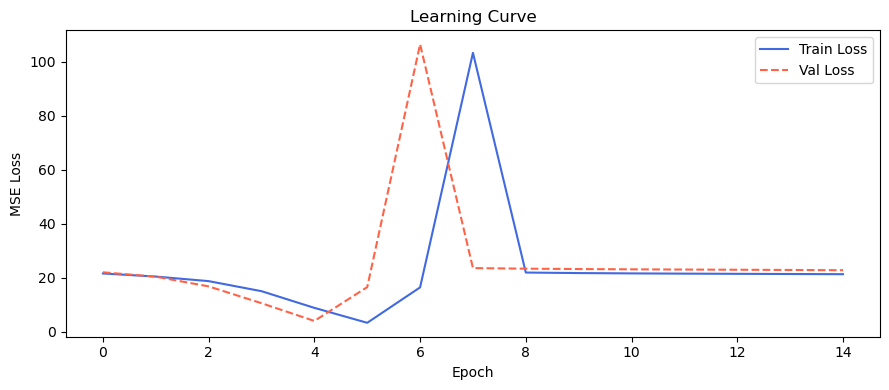

Saved → learning_curve.png


In [6]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label='Train Loss', color='royalblue')
plt.plot(val_losses,   label='Val Loss',   color='tomato', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning Curve')
plt.legend()
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150)
plt.show()
print('Saved → learning_curve.png')

Validation R²   : 0.0084
Validation RMSE : 4.7792


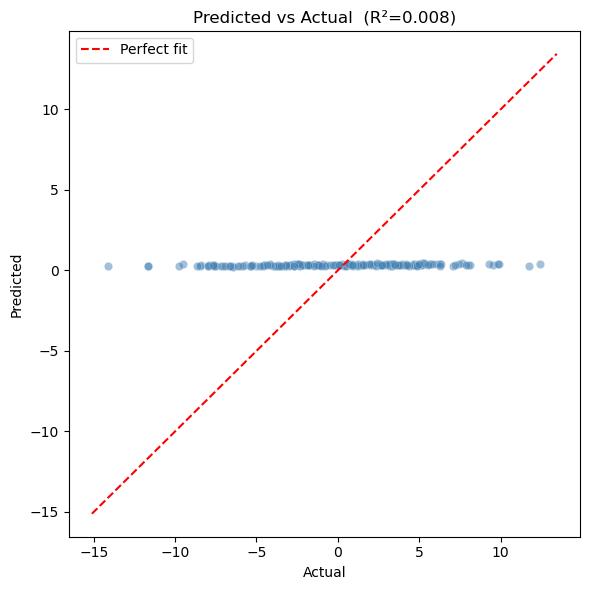

Saved → pred_vs_actual.png


In [7]:
model.eval()
with torch.no_grad():
    preds = model(X_val).cpu().numpy().flatten()
actuals = y_val.cpu().numpy().flatten()

ss_res = np.sum((actuals - preds) ** 2)
ss_tot = np.sum((actuals - actuals.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
rmse   = np.sqrt(np.mean((actuals - preds) ** 2))

print(f'Validation R²   : {r2:.4f}')
print(f'Validation RMSE : {rmse:.4f}')

plt.figure(figsize=(6, 6))
plt.scatter(actuals, preds, alpha=0.5, color='steelblue', edgecolors='white', linewidths=0.3)
lim = (min(actuals.min(), preds.min()) - 1,
       max(actuals.max(), preds.max()) + 1)
plt.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect fit')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Predicted vs Actual  (R²={r2:.3f})')
plt.legend()
plt.tight_layout()
plt.savefig('pred_vs_actual.png', dpi=150)
plt.show()
print('Saved → pred_vs_actual.png')

In [8]:
torch.save(model.state_dict(), 'model_weights.pth')
print('Model weights saved → model_weights.pth')

# ── reload and verify 
loaded_model = nn.Sequential(
    nn.Linear(nfeature, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
).to(device)
loaded_model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
loaded_model.eval()

with torch.no_grad():
    sample_input  = torch.randn(1, nfeature, device=device)
    sample_output = loaded_model(sample_input)
print(f'Inference on a random sample → {sample_output.item():.4f}')
print('✅ Model loaded and inference successful!')

Model weights saved → model_weights.pth
Inference on a random sample → 0.3592
✅ Model loaded and inference successful!
